In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline
pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

---

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*

In [3]:
crosstab = pd.crosstab(df['category'], df['boughtInLastMonth'])
crosstab

boughtInLastMonth,0,50,100,200,300,400,500,600,700,800,900,1000,2000,3000,4000,5000,6000,7000,8000,9000,10000,20000,30000,40000,50000
category,,,,,,,,,,,,,,,,,,,,,,,,,
3D Printers,239,5,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3D Printing & Scanning,4050,8,4,1,2,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Abrasive & Finishing Products,229,8,5,3,1,0,2,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0
Action Cameras,1697,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Adapters,251,1,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Wind Instruments,233,7,4,2,0,2,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
Window Treatments,216,5,2,3,1,1,0,1,1,2,2,4,1,0,0,0,0,0,0,0,0,0,0,0,0
Women,13828,2137,1182,341,115,55,47,22,7,5,5,24,1,2,0,1,0,0,0,0,0,0,0,0,0


In [4]:
category_sales = df.groupby('category')['boughtInLastMonth'].sum().sort_values(ascending=False)
category_sales.head(10)


category
Health & Personal Care    9626950
Grocery                   8442550
Beauty                    7052400
Pet Supplies              3231650
Baby                      2635150
Hair Care                 2102550
Skin Care                 2098050
Arts & Crafts             1934350
Storage & Organisation    1814350
Office Supplies           1317500
Name: boughtInLastMonth, dtype: int64

In [5]:
#the most prevelent are: 
# Health & Personal Care    9626950
# Grocery                   8442550
# Beauty                    7052400

2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [6]:
df['BestSeller'] = df['boughtInLastMonth'] > 0

In [7]:
contigency_table = pd.crosstab(df['category'], df['BestSeller'])
contigency_table.head()

BestSeller,False,True
category,,
3D Printers,239,9
3D Printing & Scanning,4050,17
Abrasive & Finishing Products,229,21
Action Cameras,1697,0
Adapters,251,3


In [8]:
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(contigency_table)

print(f"Chi-Square Statistic: {chi2:.2f}")
print(f"Degrees of Freedom: {dof}")
print(f"P-value: {p:.5f}")

Chi-Square Statistic: 1026653.72
Degrees of Freedom: 295
P-value: 0.00000


In [ ]:
# The chi-square indicates that the expected frequencies are very far apart, wich means that there is a enormous association
# between the category and best-seller
# Tue degrees of fredom represent the number of independent comparisons made
# The P-value represents the likelihood of seeing this pattern, wich is virtually zero

In [9]:
n = contigency_table.sum().sum()  
min_dim = min(contigency_table.shape) - 1

cramers_v = np.sqrt((chi2 / n) / min_dim)
print(cramers_v)

0.6481751889887275


In [36]:
# with this value means that the assossiation between category and best-seller status is very strong.
# it determins that the category is important for the probability of a item to be sold.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [10]:
prop_table = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')
prop_table = prop_table.sort_values(True, ascending=False)
prop_table.head()

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339


<function matplotlib.pyplot.show(close=None, block=None)>

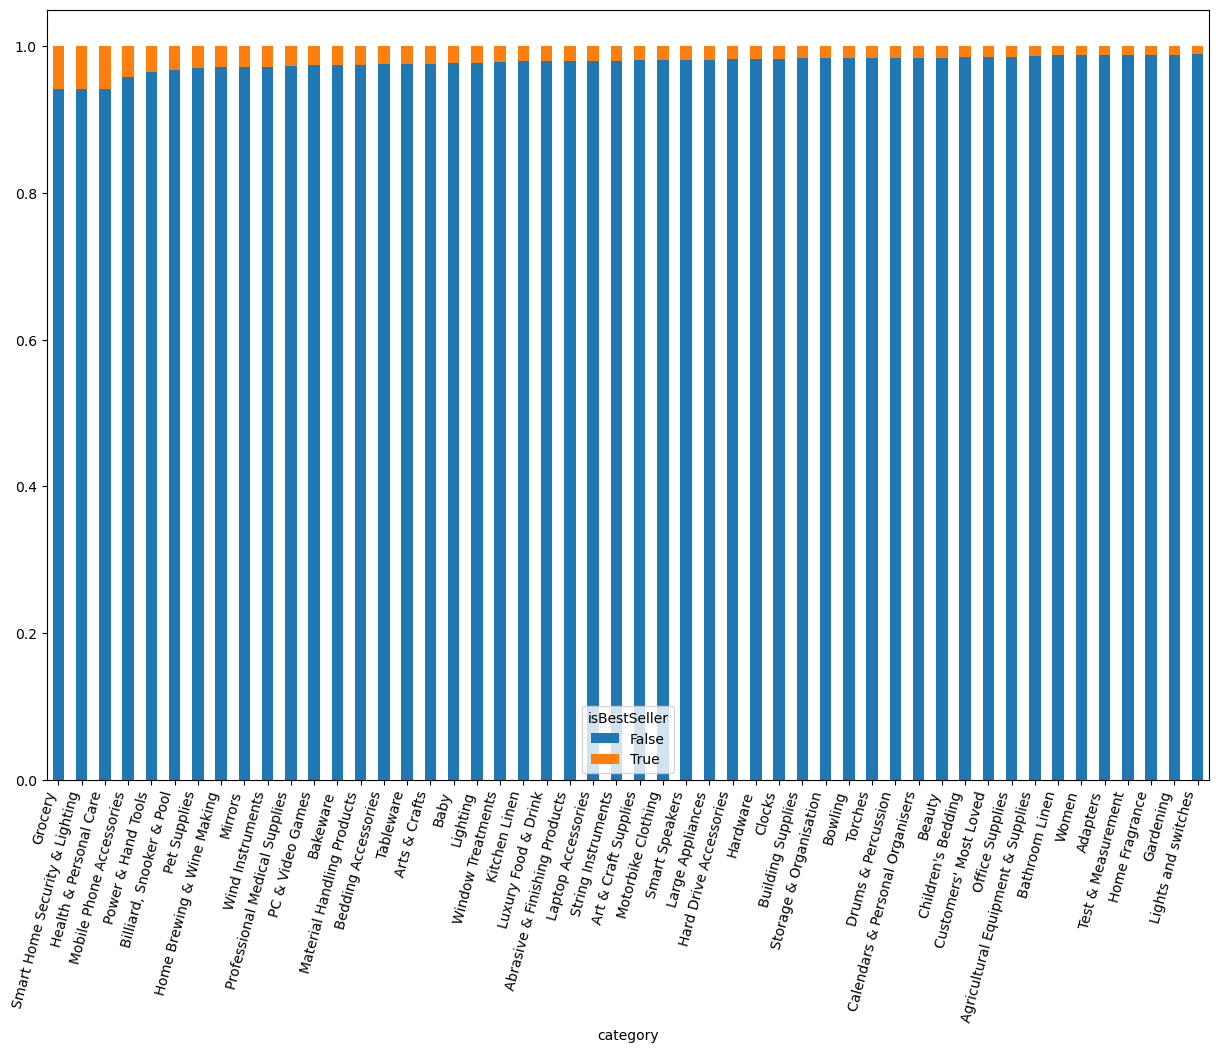

In [11]:
Top50 = prop_table.head(50)
Top50.plot(kind='bar',stacked=True, figsize = (15, 10))

plt.xticks(rotation=75, ha='right')
plt.tight_layout
plt.show

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

In [26]:
df['price'].describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [27]:
print(df['price'].unique()[:20])

[ 21.99  23.99  31.99  17.99  39.99  29.99 139.    49.99  64.99  26.99
  39.   164.99  55.99  34.8   98.95 149.99   9.99  79.99 289.    39.98]


In [28]:
df['price'] = (
    df['price']
    .astype(str)
    .str.replace('£', '', regex=False)
    .str.replace(',', '', regex=False)
)
df['price'] = pd.to_numeric(df['price'], errors='coerce')

In [29]:
df['price'].describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [30]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1={Q1}, Q3={Q3}, IQR={IQR}")
print(f"Lower={lower_bound}, Upper={upper_bound}")

Q1=9.99, Q3=45.99, IQR=36.0
Lower=-44.01, Upper=99.99000000000001


In [31]:
df = df[df['price'] > 0]

In [ ]:
df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]
print(len(df_no_outliers))

print(f"Original Size: {len(df)}")
print(f"Outlier size: {len(df_no_outliers)}")
print(f"Removed percentage: {100 * (1 - len(df_no_outliers)/len(df)):.2f}%")

2115943
Tamanho original: 2443631
Tamanho sem outliers: 2115943
Percentual removido: 13.41%


1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

In [34]:
Top20_cat = df_no_outliers['category'].value_counts().head(20).index

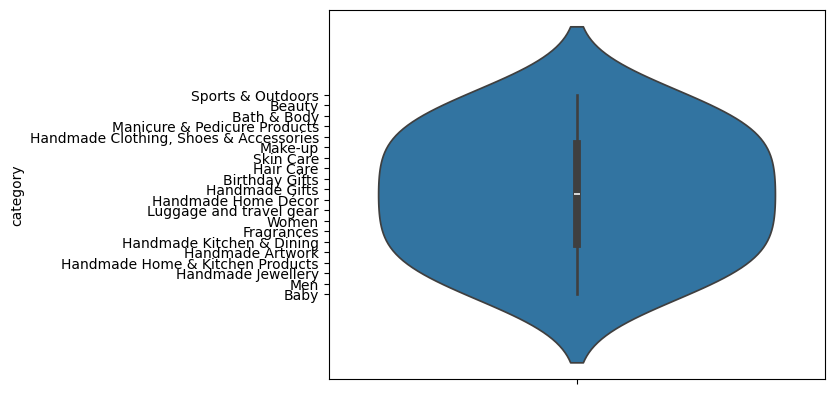

In [35]:
sns.violinplot(data=Top20_cat)
plt.show()

In [36]:
median_prices = df_no_outliers.groupby('category')['price'].median().sort_values(ascending=False)

median_prices.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

In [ ]:
# The products that have the highest median price 
# Desktop PCs               74.00
#Boxing Shoes              69.79
#Tablets                   69.00
#Graphics Cards            68.54
#Motherboards              67.92

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

In [40]:
top10_cats = df_no_outliers['category'].value_counts().head(10).index

print(top10_cats)

df_top10 = df_no_outliers[df_no_outliers['category'].isin(top10_cats)]

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='object', name='category')


In [41]:
avg_price_by_cat = (df_top10.groupby('category')['price'].mean().sort_values(ascending=False))

avg_price_by_cat

category
Sports & Outdoors                         25.172246
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

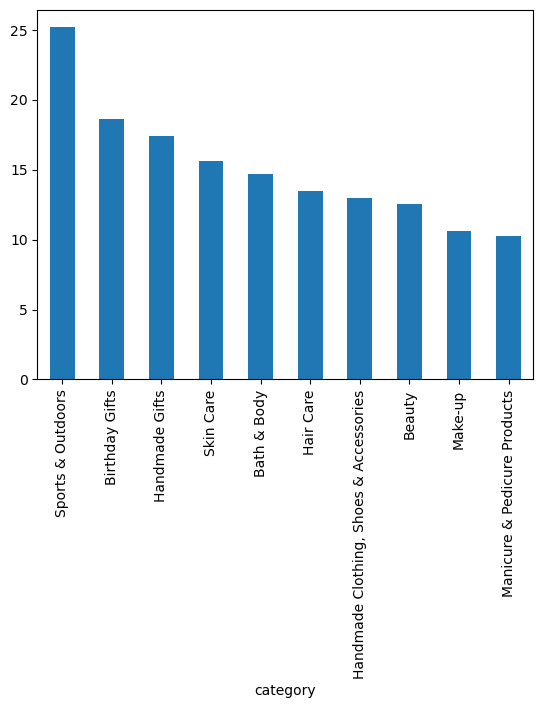

In [42]:
avg_price_by_cat.plot(kind='bar')
plt.show

In [ ]:
#The highest average price is the sports and outdoors

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [52]:
df_no_outliers.loc[:, 'stars'] = pd.to_numeric(df_no_outliers['stars'])

df_ratings = df_no_outliers.dropna(subset=['stars'])

In [51]:
top10_cats = df_ratings['category'].value_counts().head(10).index
df_top10 = df_ratings[df_ratings['category'].isin(top10_cats)]

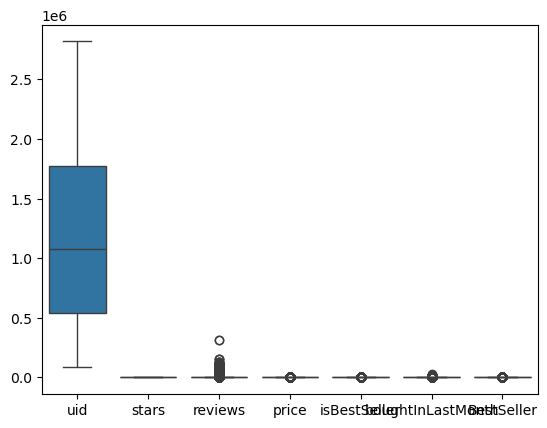

In [53]:
sns.boxplot(data=df_top10)
plt.show()

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?

In [55]:
df_no_outliers['price'] = pd.to_numeric(df_no_outliers['price'], errors='coerce')
df_no_outliers['stars'] = pd.to_numeric(df_no_outliers['stars'], errors='coerce')

df_corr = df_no_outliers.dropna(subset=['price', 'stars'])

C:\Users\vigus\AppData\Local\Temp\ipykernel_16664\1675195750.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_no_outliers['price'] = pd.to_numeric(df_no_outliers['price'], errors='coerce')
C:\Users\vigus\AppData\Local\Temp\ipykernel_16664\1675195750.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_no_outliers['stars'] = pd.to_numeric(df_no_outliers['stars'], errors='coerce')


In [56]:
corr_value = df_corr['price'].corr(df_corr['stars'], method='pearson')
print(f"Correlation between Price and Rating (stars): {corr_value:.3f}")

Correlation between Price and Rating (stars): -0.078


In [57]:
# The correlation means that the expencive products are the ones with the better reviews

2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 


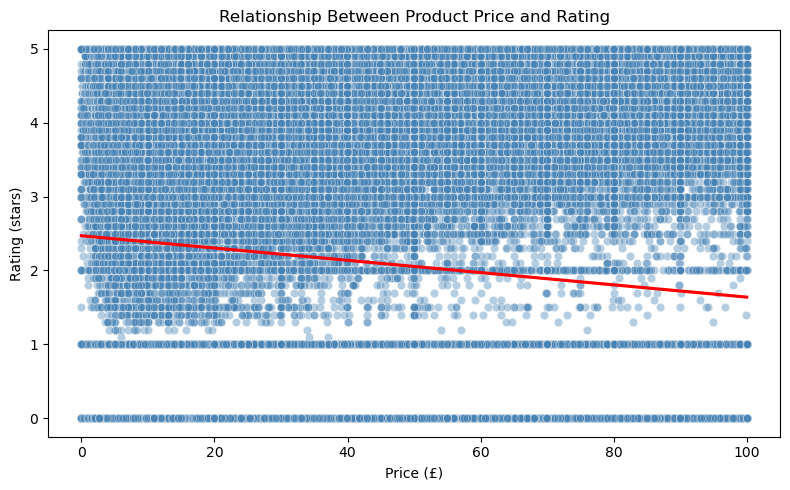

In [66]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df_no_outliers,
    x='price',
    y='stars',
    alpha=0.4,
    color='#4682b4'
)
sns.regplot(
    data=df_no_outliers,
    x='price',
    y='stars',
    scatter=False,
    color='red',
    ci=None
)
plt.title('Relationship Between Product Price and Rating')
plt.xlabel('Price (£)')
plt.ylabel('Rating (stars)')
plt.tight_layout()
plt.show()

In [70]:
# The red line is the regression
# that means that the more expensive products have worse rewies

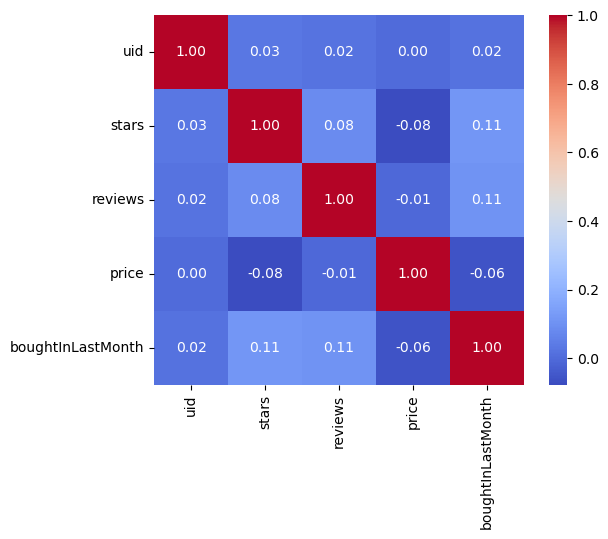

In [65]:
numeric_cols = df_no_outliers.select_dtypes(include=['number'])

corr_matrix = numeric_cols.corr()

sns.heatmap(corr_matrix,annot=True,fmt=".2f",cmap='coolwarm',square=True)

plt.show()

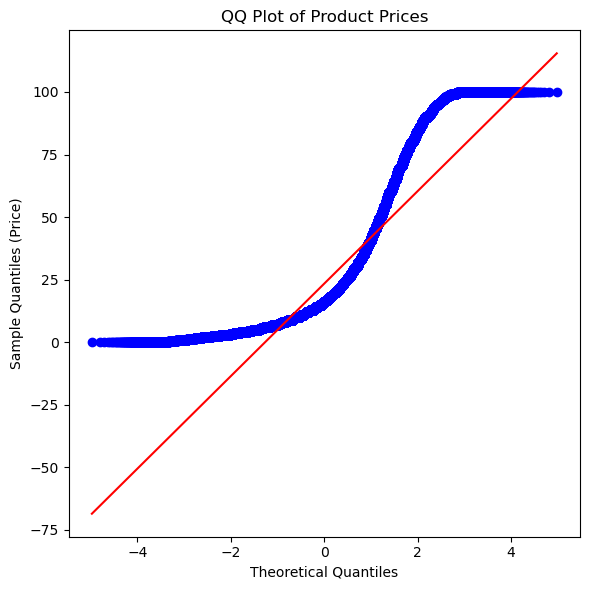

In [69]:
import scipy.stats as stats
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
stats.probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.title('QQ Plot of Product Prices')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles (Price)')
plt.tight_layout()
plt.show()

In [71]:
# It has a very low number of expensive products compare with the cheaper ones.

**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?

In [72]:
df_full = df.copy()

In [73]:
df_full['price'] = pd.to_numeric(df_full['price'], errors='coerce')
df_full['stars'] = pd.to_numeric(df_full['stars'], errors='coerce')

df_full = df_full.dropna(subset=['price', 'stars'])

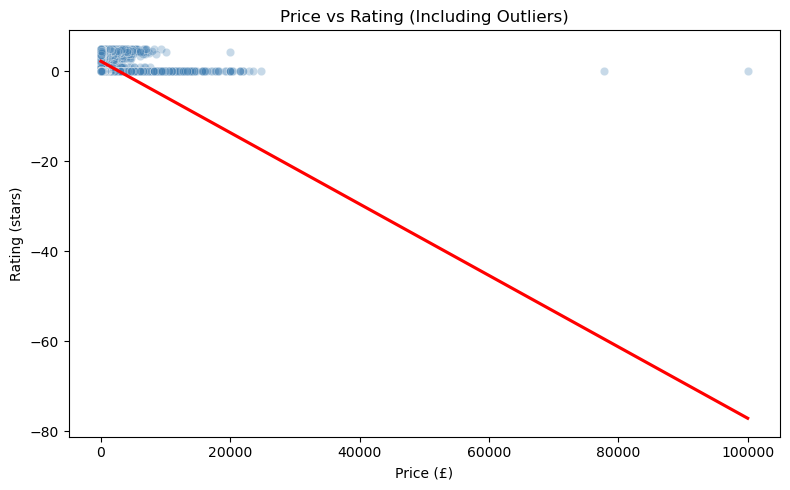

In [74]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df_full,
    x='price',
    y='stars',
    alpha=0.3,
    color='#4682b4'
)
sns.regplot(
    data=df_full,
    x='price',
    y='stars',
    scatter=False,
    color='red',
    ci=None
)
plt.title('Price vs Rating (Including Outliers)')
plt.xlabel('Price (£)')
plt.ylabel('Rating (stars)')
plt.tight_layout()
plt.show()

In [ ]:
# The graph will now be very compressed at the bottom, because some products have extremely high prices

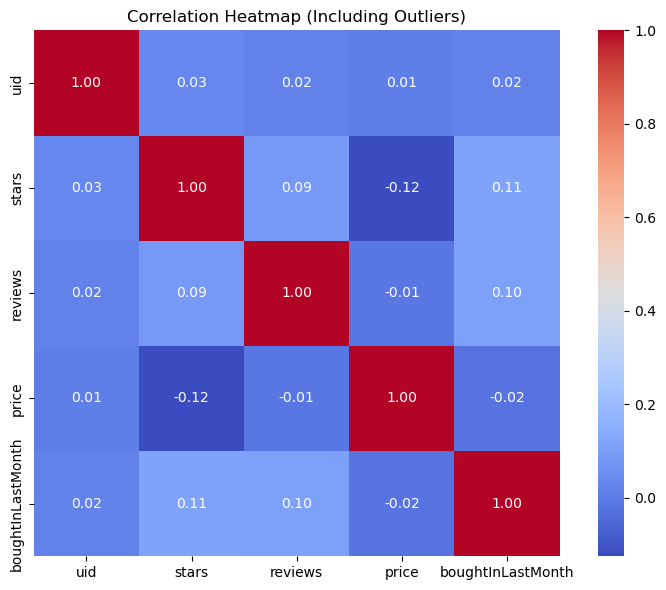

In [75]:
numeric_cols = df_full.select_dtypes(include=['number'])
corr_matrix = numeric_cols.corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title('Correlation Heatmap (Including Outliers)')
plt.tight_layout()
plt.show()

In [ ]:
# correlation between price and stars probably gets even closer to 0

# This happens because extreme price values distort the linear relationship.

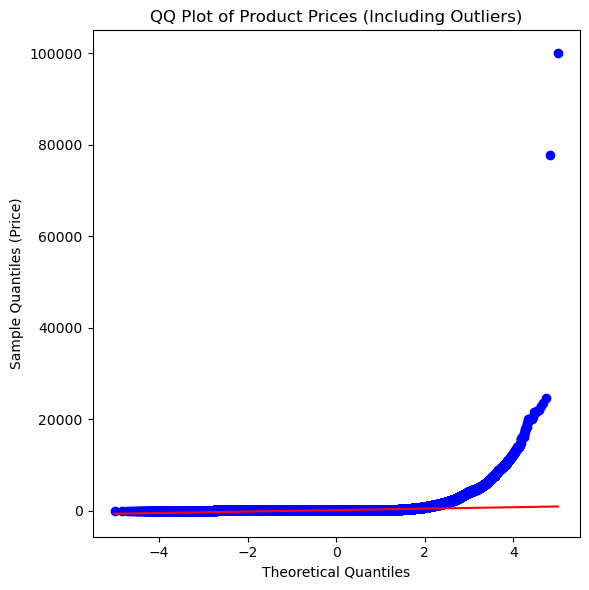

In [76]:
plt.figure(figsize=(6,6))
stats.probplot(df_full['price'], dist="norm", plot=plt)
plt.title('QQ Plot of Product Prices (Including Outliers)')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles (Price)')
plt.tight_layout()
plt.show()

In [77]:
# The right of the line will deviate sharply from the line confirming that the distribution is highly right-skewed.